# Stage 02 — Normalization and Tokenization

## Objective

Continue [Stage 01](01_eda.ipynb) with reproducible corpus preparation, stepwise normalization
measurements and four tokenization strategies on the original
[E-commerce CSV](https://www.kaggle.com/datasets/saurabhshahane/ecommerce-text-classification).
The [assignment](https://hcmus-cs-ta.github.io/lab-book/data-mining/projects/preprocessing/)
requires per-operation vocabulary/length impact and word, sentence, character and BPE
comparisons with training vocabulary, test OOV and sequence length.

This chapter re-reads raw data in a fresh kernel. It does not execute EDA or reuse its Python
variables. The source audit below independently confirms the file and population. Raw text,
labels and source record identifiers remain available throughout. No stopword removal,
MI/Naive Bayes, morphology, classifier CV or representation benchmark is performed here.

## Methodology

**Population and assessment.** Remove missing/blank text, invalid labels, all canonical groups
with conflicting labels, then exact and additional canonical duplicates. Keep the first
surviving occurrence in original CSV record order. Reuse Stage 01's fixed NFKC → lowercase →
Unicode-whitespace canonical key, which preserves digits and punctuation; it does not learn
from labels. Labels are used only to identify annotation conflicts and stratify the split.
Split canonical-unique records 80/20 with `train_test_split`, seed 42, then restore row order
inside each partition. The helper `make_text_protocol(raw)` recreates everything for later
chapters; no split cache or previous notebook is needed.

Stage 01 exposed all rows and labels. “Test” therefore means **internal post-EDA assessment**.
This chapter uses it only for the fixed tokenization coverage/OOV report (including sequence
length and processing cost), never to tune normalization, choose a seed or optimize BPE size.
Exact/canonical deduplication does not eliminate related product variants.

**Two distinct text views.** The provisional word-model normalization pipeline uses NFKC,
lowercase, recognized HTML tags, entity decoding, URL/mention handling, hashtag-marker removal,
conditional symbol handling, a declared number policy and whitespace. Its default preserves
numbers, units and identifier punctuation. A single train-only ablation removes standalone
numeric tokens. The **common tokenizer input** is lighter: NFKC, recognized markup/entity
handling and whitespace only. It preserves case, numbers, punctuation and sentence boundaries
for all four methods. Neither view overwrites raw text.

**Stepwise metrics on TRAIN.** Reuse Stage 01's lexical regex
`[^\W_]+(?:['’][^\W_]+)*` on lowercase text for every step. These diagnostic lexical types
are distinct from the benchmark's Treebank tokens. If $V_b,V_a$ are before/after type sets:

$$
\mathrm{size\ reduction}\%=100\frac{|V_b|-|V_a|}{|V_b|},\qquad
\mathrm{set\ change}\%=100\frac{|V_b\setminus V_a|+|V_a\setminus V_b|}{|V_b|}.
$$

The second measure is symmetric-difference size relative to the **before vocabulary**, not
Jaccard distance; it may exceed 100%. A vocabulary can have unchanged size but different
members. Changed-document percentage uses the fixed training N. Per step also retain
mean/median/P95 whitespace words and Unicode code-point characters, and empty-document counts.
Percentiles use NumPy's default linear interpolation. No row is dropped after normalization.

**OOV.** Token-occurrence OOV is $N_{\mathrm{unrepresented,test}}/N_{\mathrm{all,test}}$.
For word/sentence/character strategies, vocabularies contain training tokens only. For BPE,
count the actual `[UNK]` ID in encoded test output; new words are not automatically unknown
subwords. Vocabulary size, OOV and sequence length describe different units and are not an
absolute ranking of tokenizers or predictive accuracy.

## Implementation

Use the existing `.venv` / `hcmus-wids` kernel. The notebook works from repository root or
`book/text/`. If raw data is absent, obtain the original headerless CSV as described in the
[Part B overview](index.md) / README; preparation never substitutes a cleaned mirror.
Only the NLTK `punkt_tab` resource is needed. A guarded bootstrap below downloads that package
once if its English tables are missing, and raises an actionable error on failure. There is
no fake sentence tokenizer fallback. Static HTML renders saved outputs without these resources.

In [1]:
from pathlib import Path
from collections import Counter
from functools import wraps
from itertools import islice
from importlib.metadata import version
from time import perf_counter
import hashlib
import html
import os
import platform
import re
import sys
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.tokenize import PunktTokenizer, TreebankWordTokenizer
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders
from IPython.display import display, HTML

ROOT=next((p for p in (Path.cwd(),*Path.cwd().parents)
           if (p/"myst.yml").is_file() and (p/"src/text_data.py").is_file()),None)
if ROOT is None:
    raise RuntimeError("Start inside this repository.")
if Path(sys.prefix).resolve()!=(ROOT/".venv").resolve():
    raise RuntimeError("Select the existing project .venv kernel (hcmus-wids), restart, Run All.")
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
from src.text_data import LABELS, read_ecommerce, make_text_protocol
DATA_PATH=ROOT/"data/raw/ecommerce/ecommerceDataset.csv"
SEED=42
sns.set_theme(style="whitegrid",context="notebook")
plt.rcParams.update({"figure.dpi":110,"savefig.dpi":140})

def prose(text):
    safe=html.escape(text)
    return HTML("<p>"+re.sub(r"\*\*(.+?)\*\*",r"<strong>\1</strong>",safe)+"</p>")

def show_table(frame,title=None,collapse=False,**kwargs):
    body='<div style="overflow-x:auto">'+frame.to_html(escape=True,**kwargs)+'</div>'
    if collapse: body=f"<details><summary>{html.escape(title or 'Supporting table')}</summary>{body}</details>"
    elif title: body=f"<p><strong>{html.escape(title)}</strong></p>"+body
    display(HTML(body))

print("Python",platform.python_version(),"|",platform.system(),platform.machine(),"| logical CPUs",os.cpu_count())
show_table(pd.DataFrame({"package":["pandas","scikit-learn","nltk","tokenizers"],
                         "version":[version(p) for p in ["pandas","scikit-learn","nltk","tokenizers"]]}),index=False)

Python 3.13.3 | Darwin arm64 | logical CPUs 8


package,version
pandas,3.1.0
scikit-learn,1.9.1
nltk,3.10.4
tokenizers,0.23.3


In [2]:
NLTK_DIR=ROOT/".cache/nltk_data"
nltk.data.path.insert(0,str(NLTK_DIR))
resource="tokenizers/punkt_tab/english/"
try:
    punkt_path=nltk.data.find(resource)
    resource_preparation="existing English punkt_tab tables reused"
except LookupError:
    try:
        nltk.download("punkt_tab",download_dir=str(NLTK_DIR),quiet=True,raise_on_error=True)
        punkt_path=nltk.data.find(resource)
        resource_preparation="downloaded punkt_tab once; English tables loaded"
    except Exception:
        raise RuntimeError("Missing NLTK English punkt_tab. With .venv active, run: "
                           "python -m nltk.downloader -d .cache/nltk_data punkt_tab; then rerun. "
                           "Check network access; no fallback tokenizer is used.") from None
sentence_tokenizer=PunktTokenizer("english")
word_tokenizer=TreebankWordTokenizer()
print(resource_preparation)
resource_hashes=[]
for name in ["abbrev_types.txt","collocations.tab","ortho_context.tab","sent_starters.txt"]:
    with punkt_path.join(name).open(encoding="utf-8") as resource_file:
        digest=hashlib.sha256(resource_file.read().encode("utf-8")).hexdigest()
    resource_hashes.append({"English resource file":name,"SHA-256":digest})
show_table(pd.DataFrame(resource_hashes),"Boundary-model provenance",collapse=True,index=False)

existing English punkt_tab tables reused


English resource file,SHA-256
abbrev_types.txt,92a3e070f43d9b4c5534758ca40ad7343b04e7e29bfe0c2eb658a39445a4f779
collocations.tab,8e2da1225e4dd2cc9dba261ee231ccb134859e21b46006e7f472c5ee269af0cf
ortho_context.tab,4bbcca25ed3d3f06c02402abf8419b9f033b8adc06e7b482eca4e45f81a5dc4c
sent_starters.txt,f3f8535483e1dba487241b764945168123bca3209a9645e59acd1225dc76edac


### Stateless normalization functions

Functions below are deliberately small and visible. Missing scalar inputs remain `pd.NA`,
empty strings remain empty, and non-string observed values raise an error. They never turn
missingness into the literal string `nan`. No learned parameters, labels or test statistics
enter these operations. Individual step rationale and measured results follow in Results.

In [3]:
def preserve_missing(function):
    @wraps(function)
    def safe(value):
        if value is None or pd.isna(value): return pd.NA
        if not isinstance(value,str): raise TypeError("Expected a string or a missing scalar")
        return function(value)
    return safe

@preserve_missing
def unicode_nfkc(text): return unicodedata.normalize("NFKC",text)

@preserve_missing
def lowercase(text): return text.lower()

# Fixed common HTML tag names, followed by a tag boundary; quoted attributes are supported.
# No generic <.*?> deletion: <5, <10cm> and unknown tag-shaped strings survive this step.
HTML_TAG_RE=re.compile(
    r"<\s*/?\s*(?:a|abbr|b|blockquote|br|div|em|font|h[1-6]|hr|i|img|li|ol|p|s|small|span|strong|sub|sup|table|tbody|td|th|thead|tr|u|ul)"
    r"(?=[\s/>])(?:[^<>\"']|\"[^\"]*\"|'[^']*')*>",re.IGNORECASE)

@preserve_missing
def remove_html_tags(text): return HTML_TAG_RE.sub(" ",text)

@preserve_missing
def decode_entities(text): return html.unescape(text)

URL_RE=re.compile(r"\b(?:https?://|www\.)[^\s<>]+",re.IGNORECASE)
@preserve_missing
def remove_urls(text):
    def replace(match):
        value=match.group();trimmed=value.rstrip(".,;:!?)]}")
        return " "+value[len(trimmed):]  # Preserve candidate sentence-final punctuation.
    return URL_RE.sub(replace,text)

@preserve_missing
def remove_mentions(text): return re.sub(r"(?<!\w)@\w+"," ",text)

@preserve_missing
def remove_hashtag_marker(text): return re.sub(r"(?<!\w)#(?=\w)","",text)

# Keep identifier/measurement punctuation, rather than erasing all non-alphanumerics.
KEPT_SYMBOLS=set("'\"_-./+%<>=×°±")
SYMBOL_TRANSLATION=str.maketrans({"’":"'","‘":"'","“":'"',"”":'"',"–":"-","—":"-"})
@preserve_missing
def conditional_symbols(text):
    mapped=text.translate(SYMBOL_TRANSLATION)
    return "".join(c if c.isalnum() or c.isspace() or c in KEPT_SYMBOLS else " " for c in mapped)

@preserve_missing
def keep_numbers(text): return text

STANDALONE_NUMBER_RE=re.compile(r"(?<!\S)[+-]?\d+(?:[.,]\d+)*(?!\S)")
@preserve_missing
def drop_standalone_numbers(text): return STANDALONE_NUMBER_RE.sub(" ",text)

@preserve_missing
def normalize_whitespace(text): return " ".join(text.split())

LEXICAL_RE=re.compile(r"[^\W_]+(?:['’][^\W_]+)*",re.UNICODE)
def lexical_tokens(text): return LEXICAL_RE.findall(text.lower())

def light_input(text):
    # Shared benchmark view: leave case, punctuation, handles, URLs and numbers intact.
    for function in [unicode_nfkc,remove_html_tags,decode_entities,normalize_whitespace]:
        text=function(text)
    return text

In [4]:
def fit_bpe(train_texts,*,vocab_size=8000,min_frequency=2):
    # Only this iterator is consumed for training; no test argument or external tokenizer.
    tokenizer=Tokenizer(models.BPE(unk_token="[UNK]"))
    tokenizer.normalizer=None  # The common light input has already been prepared.
    tokenizer.pre_tokenizer=pre_tokenizers.ByteLevel(add_prefix_space=False,use_regex=True)
    tokenizer.decoder=decoders.ByteLevel()
    trainer=trainers.BpeTrainer(vocab_size=vocab_size,min_frequency=min_frequency,
                               special_tokens=["[UNK]"],
                               initial_alphabet=sorted(pre_tokenizers.ByteLevel.alphabet()),
                               show_progress=False)
    tokenizer.train_from_iterator(train_texts,trainer=trainer)
    # No post-processor, automatic special tokens, truncation or padding.
    return tokenizer

def oov_counts(counter,vocabulary):
    total=sum(counter.values())
    unknown=sum(count for token,count in counter.items() if token not in vocabulary)
    return unknown,total,unknown/total if total else np.nan

## Results

### Source audit, corpus flow and frozen split

`row_id` means **zero-based CSV record position**, not physical line number (quoted CSV
records may span lines). The raw frame remains unchanged; helper copies retain the original
`text`, `label`, `row_id` and a separate canonical key. Conflicting-label groups are removed
as a whole, with no majority-vote relabeling. Source references check versions, not results
substituted for measurements.

In [5]:
if not DATA_PATH.is_file():
    raise FileNotFoundError("Download the original Kaggle ecommerceDataset.csv to data/raw/ecommerce/. "
                            "See README for guarded preparation; do not substitute a cleaned mirror.")
raw_sha256_before=hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
raw=read_ecommerce(DATA_PATH)
raw_snapshot=raw.copy(deep=True)
source_audit=pd.Series({"raw_rows":len(raw),"columns":raw.shape[1],"file_bytes":DATA_PATH.stat().st_size,
                        "MD5":hashlib.md5(DATA_PATH.read_bytes()).hexdigest(),"SHA-256":raw_sha256_before},name="observed")
show_table(source_audit.to_frame())
reference_sha="1d44be1780bc9558f40ab4cee5b32051ddfe90647cd525b9652b47cdb233593f"
if raw_sha256_before!=reference_sha:
    display(prose("**VERSION DIFFERENCE:** actual source differs from the verified Stage 01 file. "
                  "All results below describe these bytes; no counts are forced to match."))
protocol=make_text_protocol(raw,test_size=.2,seed=SEED)
corpus,train,test=(protocol[k] for k in ["corpus","train","test"])
show_table(protocol["flow"],"Sequential data flow — removals are not double-counted",index=False)
conflict_report=pd.Series({"conflicting_canonical_groups":len(protocol["conflicts"]),
                           "rows_in_conflicting_groups":int(protocol["conflicts"].rows.sum())},name="measured")
show_table(conflict_report.to_frame())
show_table(protocol["conflicts"].head(5).reset_index().assign(
    canonical_key=lambda f:f.canonical_key.str.slice(0,160)),"Conflicting groups (escaped excerpts; none if empty)",collapse=True,index=False)
assert len(corpus)>=10000 and set(corpus.label)==set(LABELS)
assert set(train.row_id).isdisjoint(test.row_id)
assert set(train.canonical_key).isdisjoint(test.canonical_key)
assert set(train.row_id)|set(test.row_id)==set(corpus.row_id)
assert corpus.canonical_key.is_unique and corpus.text.is_unique
assert train.text.equals(raw.loc[train.row_id,"text"].reset_index(drop=True))
split_table=pd.DataFrame({"corpus_N":corpus.label.value_counts(),"train_N":train.label.value_counts(),
                          "test_N":test.label.value_counts()}).reindex(LABELS)
split_table["train_pct"]=100*split_table.train_N/len(train)
split_table["test_pct"]=100*split_table.test_N/len(test)
show_table(split_table.round(3),"Class support in the canonical-unique corpus")
split_checks=pd.Series({"train_N":len(train),"test_N":len(test),"test_fraction":len(test)/len(corpus),
                         "row_ID_overlap":len(set(train.row_id)&set(test.row_id)),
                         "canonical_group_overlap":len(set(train.canonical_key)&set(test.canonical_key)),
                         "seed":SEED},name="observed")
show_table(split_checks.to_frame())
partition_hashes={name:hashlib.sha256(frame.row_id.to_numpy(dtype="<i8").tobytes()).hexdigest()
                  for name,frame in [("train",train),("test",test)]}
show_table(pd.Series(partition_hashes,name="SHA256_of_sorted_little_endian_int64_row_IDs").to_frame(),
           "Partition membership fingerprints",collapse=True)
display(prose(f"**Observed:** {len(corpus):,} canonical-unique examples remain, with all four labels. "
              f"Train has **{len(train):,}**, internal assessment **{len(test):,}** "
              f"({len(test)/len(corpus):.2%}); row-ID and canonical-key overlap are both zero. "
              "Recreate this membership with make_text_protocol(raw, test_size=.2, seed=42), "
              "without executing this notebook or reading a cache."))

,observed
raw_rows,50425
columns,2
file_bytes,36949114
MD5,6f2cfdb475096244916aeed6f776c1a6
SHA-256,1d44be1780bc9558f40ab4cee5b32051ddfe90647cd525b9652b47cdb233593f


step,removed_rows,remaining_rows
raw CSV,0,50425
missing / blank text,1,50424
missing / invalid label,0,50424
all conflicting-label canonical groups,0,50424
exact duplicate rows after first,22622,27802
additional canonical duplicates after first,50,27752


,measured
conflicting_canonical_groups,0
rows_in_conflicting_groups,0


canonical_key,rows,labels


,corpus_N,train_N,test_N,train_pct,test_pct
label,,,,,
Household,10562,8449,2113,38.057,38.065
Books,6220,4976,1244,22.413,22.41
Clothing & Accessories,5666,4533,1133,20.418,20.411
Electronics,5304,4243,1061,19.112,19.114


,observed
train_N,22201.000000
test_N,5551.000000
test_fraction,0.200022
row_ID_overlap,0.000000
canonical_group_overlap,0.000000
seed,42.000000


,SHA256_of_sorted_little_endian_int64_row_IDs
train,b36f8f64739c881a5beb35e57b0a5068f3a319733506aca0b34a89ccdac0fe2c
test,737d4fab65e776bce15718b1e512546b547a6bc53802d7f3228933293084cce6


### Near-duplicate boundary

Stage 01's saved, bounded prefix/Jaccard illustration found related descriptions beyond exact
keys. This chapter performs a **training-only** counterpart: inspect at most 300 adjacent
canonical keys with the same first 60 characters, fixed lexicographic ordering, and record
whitespace-token-set Jaccard ≥0.90. This deliberately biased candidate set demonstrates
remaining product/template similarity; it is not a corpus duplicate-rate estimate. It does
not alter membership, inspect test text for tuning, build a dense all-pairs matrix or claim
to remove all variants. Shared family context can still cross the frozen boundary.

In [6]:
ordered=sorted(train.canonical_key)
pairs=islice(((a,b) for a,b in zip(ordered,ordered[1:]) if a[:60]==b[:60]),300)
train_key_rows=train.set_index("canonical_key")
near_examples=[];near_candidates=0
for a,b in pairs:
    near_candidates+=1
    left,right=set(a.split()),set(b.split())
    jaccard=len(left&right)/len(left|right)
    if jaccard>=.90:
        difference=next((i for i,(x,y) in enumerate(zip(a,b)) if x!=y),min(len(a),len(b)))
        start=max(0,difference-35)
        near_examples.append({"row_A":int(train_key_rows.loc[a,"row_id"]),
                              "row_B":int(train_key_rows.loc[b,"row_id"]),"Jaccard":jaccard,
                              "canonical_window_A":a[start:start+150],"canonical_window_B":b[start:start+150]})
near_table=pd.DataFrame(near_examples)
show_table(near_table.head(3).round(4),"Related training descriptions after canonical deduplication",index=False)
display(prose(f"**Observed:** {len(near_examples)} of {near_candidates} biased candidate pairs meet "
              "the illustrative threshold. Exact/canonical uniqueness is therefore a limited boundary. "
              "Future CV should consider family-aware sensitivity and cross-partition match review "
              "before interpreting model generalization; this chapter does not retune the split."))

row_A,row_B,Jaccard,canonical_window_A,canonical_window_B
11501,11505,0.9394,to meal server cooking tools color brown material:wood; brand name:none; length:about 21cm; flatware type:spoons; feature 1:kids spoon; feature 2:feat,to meal server cooking tools color white material:wood; brand name:none; length:about 21cm; flatware type:spoons; feature 1:kids spoon; feature 2:feat
21742,21764,0.9828,"solved papers (2018-1979) iit jee mathematics about the author an editorial team of highly skilled professionals at arihant, works hand in glove to e","solved papers (2018-1979) iit jee physics about the author an editorial team of highly skilled professionals at arihant, works hand in glove to ensur"
19441,23146,0.9939,"tory of fantasy.”—los angeles times about the author george r. r. martin is the #1 new york times bestselling author of many novels, including the acc",tory of fantasy.”—los angeles timesfrom the hardcover edition. about the author george r. r. martin is the #1 new york times bestselling author of man


### TRAIN normalization measurements

For every operation, compare its output with the immediately previous view, always on the
same training records. Lowercased lexical diagnostics intentionally match Stage 01: consequently
lowercase can change documents while showing zero lexical vocabulary change. All intermediate
views stay separate from the raw frame. Tables report empty outputs rather than silently
removing them. Detailed per-step tables remain expandable; the final compact tables collect
all operations in order.

In [7]:
train_views={"raw":train.text.copy()}
step_records=[]
step_examples=[]

def vocabulary(series):
    types=set()
    for text in series: types.update(lexical_tokens(text))
    return types

def describe_lengths(series):
    words=series.map(lambda t:len(t.split())).to_numpy()
    chars=series.str.len().to_numpy(dtype=np.int64)
    return {"word_mean":words.mean(),"word_median":np.median(words),"word_P95":np.quantile(words,.95),
            "char_mean":chars.mean(),"char_median":np.median(chars),"char_P95":np.quantile(chars,.95),
            "empty_total":int(series.str.strip().eq("").sum())}

current_name="raw"
current_vocab=vocabulary(train.text)
raw_length_stats=describe_lengths(train.text)

def apply_step(name,function,risk):
    global current_name,current_vocab
    before=train_views[current_name];after=before.map(function)
    assert after.index.equals(before.index) and after.notna().all()
    after_vocab=vocabulary(after)
    lost=current_vocab-after_vocab;new=after_vocab-current_vocab
    changed=before.ne(after)
    record={"step":name,"changed_N":int(changed.sum()),"changed_pct":100*changed.mean(),
            "V_before":len(current_vocab),"V_after":len(after_vocab),"types_lost":len(lost),"types_new":len(new),
            "vocab_size_reduction_pct":100*(len(current_vocab)-len(after_vocab))/len(current_vocab),
            "vocab_set_change_pct":100*(len(lost)+len(new))/len(current_vocab),
            "became_empty":int((before.str.strip().ne("") & after.str.strip().eq("")).sum()),
            **describe_lengths(after)}
    step_records.append(record)
    if changed.any():
        index=changed.index[changed][0]
        a,b=before.loc[index],after.loc[index]
        difference=next((i for i,(x,y) in enumerate(zip(a,b)) if x!=y),min(len(a),len(b)))
        start=max(0,difference-40)
        step_examples.append({"step":name,"row_id":int(train.loc[index,"row_id"]),
                              "before_window":repr(a[start:start+200]),"after_window":repr(b[start:start+200])})
    train_views[name]=after
    current_name,current_vocab=name,after_vocab
    display(prose(f"**Measured:** {record['changed_N']:,}/{len(train):,} documents change "
                  f"({record['changed_pct']:.3f}%); vocabulary {record['V_before']:,} → {record['V_after']:,}; "
                  f"lost/new types {len(lost):,}/{len(new):,}; set change {record['vocab_set_change_pct']:.3f}%; "
                  f"new empty outputs {record['became_empty']}. **Interpretation:** {risk}"))
    show_table(pd.DataFrame([record]).round(4),f"{name}: all measured fields",collapse=True,index=False)

#### NFKC

Compatibility normalization folds full-width forms and ligatures while keeping numerical content. It can alter display distinctions, so raw strings remain available.

In [8]:
apply_step('NFKC',unicode_nfkc,'Review compatibility folds before interpreting identifiers as identical.')

step,changed_N,changed_pct,V_before,V_after,types_lost,types_new,vocab_size_reduction_pct,vocab_set_change_pct,became_empty,word_mean,word_median,word_P95,char_mean,char_median,char_P95,empty_total
NFKC,1795,8.0852,72746,72801,78,133,-0.0756,0.2901,0,111.8782,76.0,305.0,699.9307,474.0,1898.0,0


#### lowercase

Lowercase creates a uniform case view but can erase meaningful brand/model capitalization. The lexical metric already folds case, so this step can have zero lexical set change despite changed documents.

In [9]:
apply_step('lowercase',lowercase,'Zero lexical change here follows the declared lowercase diagnostic; it does not mean case information was preserved.')

step,changed_N,changed_pct,V_before,V_after,types_lost,types_new,vocab_size_reduction_pct,vocab_set_change_pct,became_empty,word_mean,word_median,word_P95,char_mean,char_median,char_P95,empty_total
lowercase,22199,99.991,72801,72801,0,0,0.0,0.0,0,111.8782,76.0,305.0,699.9307,474.0,1898.0,0


#### HTML tags

Remove only a fixed list of common HTML tag names with tag boundaries, preserving tag contents. Unknown tag-like strings and comparisons such as `<5` or `<10cm>` survive. Replacing tags with spaces prevents word concatenation. A legitimate variable named `b` inside angle brackets can remain ambiguous.

In [10]:
apply_step('HTML tags',remove_html_tags,'This allowlist reduces markup candidates without claiming every recognized tag is noise. Tables/examples retain evidence for review.')

step,changed_N,changed_pct,V_before,V_after,types_lost,types_new,vocab_size_reduction_pct,vocab_set_change_pct,became_empty,word_mean,word_median,word_P95,char_mean,char_median,char_P95,empty_total
HTML tags,13,0.0586,72801,72801,0,0,0.0,0.0,0,111.8782,76.0,305.0,699.9214,474.0,1898.0,0


#### entities

Decode HTML entities once after removing recognized tags. Thus `&lt;5` becomes the literal comparison `<5` rather than disappearing as markup. Encoded tags that become visible at this point remain text: there is no second broad tag-removal pass.

In [11]:
apply_step('entities',decode_entities,'Entity decoding may introduce punctuation or compatibility-like forms; preserving comparisons takes priority over erasing every angle-bracket expression.')

step,changed_N,changed_pct,V_before,V_after,types_lost,types_new,vocab_size_reduction_pct,vocab_set_change_pct,became_empty,word_mean,word_median,word_P95,char_mean,char_median,char_P95,empty_total
entities,28,0.1261,72801,72797,4,0,0.0055,0.0055,0,111.8785,76.0,305.0,699.8878,474.0,1898.0,0


#### URLs

Replace HTTP(S)/www URLs with a space and preserve candidate trailing sentence punctuation. A URL can contain product provenance or useful identity; punctuation trimming is a heuristic and may also trim a legitimate path suffix.

In [12]:
apply_step('URLs',remove_urls,'This is a provisional URL-exclusion baseline; retain raw provenance and validate the information trade-off later.')

step,changed_N,changed_pct,V_before,V_after,types_lost,types_new,vocab_size_reduction_pct,vocab_set_change_pct,became_empty,word_mean,word_median,word_P95,char_mean,char_median,char_P95,empty_total
URLs,149,0.6711,72797,72652,145,0,0.1992,0.1992,0,111.8761,76.0,305.0,699.6617,474.0,1898.0,0


#### mentions

Remove standalone mention-shaped `@word` matches. The negative word-character lookbehind avoids deleting the `@` part of ordinary email addresses, but product references such as `@50` can still match.

In [13]:
apply_step('mentions',remove_mentions,'A mention-shaped match is not a verified social handle; observed examples determine whether a narrower future rule is needed.')

step,changed_N,changed_pct,V_before,V_after,types_lost,types_new,vocab_size_reduction_pct,vocab_set_change_pct,became_empty,word_mean,word_median,word_P95,char_mean,char_median,char_P95,empty_total
mentions,67,0.3018,72652,72622,30,0,0.0413,0.0413,0,111.8737,76.0,305.0,699.6285,474.0,1898.0,0


#### hashtags

Remove only the leading `#` marker of a standalone hashtag-shaped token; retain its content. This addresses hashtag syntax while preserving product codes and words. It intentionally differs from deleting the whole token.

In [14]:
apply_step('hashtags',remove_hashtag_marker,'Marker removal can preserve a useful code or keyword; lexical counts can stay unchanged because the diagnostic tokenizer already treats # as a boundary.')

step,changed_N,changed_pct,V_before,V_after,types_lost,types_new,vocab_size_reduction_pct,vocab_set_change_pct,became_empty,word_mean,word_median,word_P95,char_mean,char_median,char_P95,empty_total
hashtags,140,0.6306,72622,72622,0,0,0.0,0.0,0,111.8737,76.0,305.0,699.6081,474.0,1898.0,0


#### symbols

Map curly quotes and long dashes to straight forms. Keep Unicode alphanumerics/whitespace plus apostrophes, quotes, underscore, hyphen, decimal dot, slash, plus, percent, comparators, ×, ° and ±. Replace other symbols/punctuation with spaces. This conditional word-model view can discard sentence delimiters; it is not the tokenizer benchmark input.

In [15]:
apply_step('symbols',conditional_symbols,'Removing decorative symbols can also lose meaning, while preserving measurement/identifier punctuation limits some damage. No classifier validates this choice yet.')

step,changed_N,changed_pct,V_before,V_after,types_lost,types_new,vocab_size_reduction_pct,vocab_set_change_pct,became_empty,word_mean,word_median,word_P95,char_mean,char_median,char_P95,empty_total
symbols,19873,89.514,72622,72299,848,525,0.4448,1.8906,0,112.2667,76.0,306.0,699.6081,474.0,1898.0,0


#### numbers

Default: preserve every digit, including standalone numbers, decimals, units and mixed model IDs. No number is automatically deemed useless. The explicitly measured alternative below removes only whitespace-delimited numeric tokens, leaving attached units and letter-number IDs intact.

In [16]:
apply_step('numbers',keep_numbers,'Zero default change is intentional. Standalone sizes and quantities can identify products, so the number-removal alternative is descriptive rather than a chosen winner.')

step,changed_N,changed_pct,V_before,V_after,types_lost,types_new,vocab_size_reduction_pct,vocab_set_change_pct,became_empty,word_mean,word_median,word_P95,char_mean,char_median,char_P95,empty_total
numbers,0,0.0,72299,72299,0,0,0.0,0.0,0,112.2667,76.0,306.0,699.6081,474.0,1898.0,0


#### whitespace

Collapse Unicode whitespace runs to one ASCII space and strip ends. No records are dropped. This removes formatting/layout information and can alter the interpretation of list/table descriptions.

In [17]:
apply_step('whitespace',normalize_whitespace,'Whitespace cleanup gives a stable linear input, with raw formatting retained for provenance.')

step,changed_N,changed_pct,V_before,V_after,types_lost,types_new,vocab_size_reduction_pct,vocab_set_change_pct,became_empty,word_mean,word_median,word_P95,char_mean,char_median,char_P95,empty_total
whitespace,20254,91.2301,72299,72299,0,0,0.0,0.0,0,112.2667,76.0,306.0,683.6528,463.0,1852.0,0


### Combined impact, number-policy ablation and empty/meaning risks

The primary comparison below is TRAIN only. “Lost/new” means lexical types relative to the
previous step, not removed token occurrences. Size reduction and set change use different
formulas and must not be conflated. Length plots retain all training records on log1p axes.
Default output is an auditable provisional baseline for Stage 03–04, not a performance winner.

The alternative removes only whitespace-delimited signed integers/decimal/grouped numeric
strings after conditional symbol handling, then normalizes whitespace. It keeps `usb3`,
`10cm` and mixed product IDs, but removes standalone `10` or `3.5`, potentially erasing sizes
and quantities. Both alternatives use identical records; test OOV never chooses this policy.

Step,Changed documents,V before → after,Lost / new,Set Δ %,Size ↓ %
NFKC,"1,795 (8.09%)","72,746 → 72,801",78 / 133,0.290,-0.076
lowercase,"22,199 (99.99%)","72,801 → 72,801",0 / 0,0.000,0.000
HTML tags,13 (0.06%),"72,801 → 72,801",0 / 0,0.000,0.000
entities,28 (0.13%),"72,801 → 72,797",4 / 0,0.005,0.005
URLs,149 (0.67%),"72,797 → 72,652",145 / 0,0.199,0.199
mentions,67 (0.30%),"72,652 → 72,622",30 / 0,0.041,0.041
hashtags,140 (0.63%),"72,622 → 72,622",0 / 0,0.000,0.000
symbols,"19,873 (89.51%)","72,622 → 72,299",848 / 525,1.891,0.445
numbers,0 (0.00%),"72,299 → 72,299",0 / 0,0.000,0.000
whitespace,"20,254 (91.23%)","72,299 → 72,299",0 / 0,0.000,0.000


step,word_mean,word_median,word_P95
raw,111.88,76.0,305.0
NFKC,111.88,76.0,305.0
lowercase,111.88,76.0,305.0
HTML tags,111.88,76.0,305.0
entities,111.88,76.0,305.0
URLs,111.88,76.0,305.0
mentions,111.87,76.0,305.0
hashtags,111.87,76.0,305.0
symbols,112.27,76.0,306.0
numbers,112.27,76.0,306.0


step,char_mean,char_median,char_P95
raw,699.86,474.0,1898.0
NFKC,699.93,474.0,1898.0
lowercase,699.93,474.0,1898.0
HTML tags,699.92,474.0,1898.0
entities,699.89,474.0,1898.0
URLs,699.66,474.0,1898.0
mentions,699.63,474.0,1898.0
hashtags,699.61,474.0,1898.0
symbols,699.61,474.0,1898.0
numbers,699.61,474.0,1898.0


step,empty_total,became_empty
raw,0,0
NFKC,0,0
lowercase,0,0
HTML tags,0,0
entities,0,0
URLs,0,0
mentions,0,0
hashtags,0,0
symbols,0,0
numbers,0,0


step,row_id,before_window,after_window
NFKC,2,"' \xa0|\xa0 Size:35 cm x 50 cm x 3 cm Overview a beautiful painting involves the action or skill of using paint in the right manner; hence, '","' | Size:35 cm x 50 cm x 3 cm Overview a beautiful painting involves the action or skill of using paint in the right manner; hence, '"
lowercase,0,'Paper Plane Design Framed Wall Hanging Motivational Office Decor Art Prints (8.7 X 8.7 inch) - Set of 4 Painting made up in synthetic frame with uv textured print which gives multi effects and attract','paper plane design framed wall hanging motivational office decor art prints (8.7 x 8.7 inch) - set of 4 painting made up in synthetic frame with uv textured print which gives multi effects and attract'
HTML tags,3790,"""'t affect the appearance of the cabinets</span></li> suitable for babies 6 months-5 years old can be used on the refrigerator, cabinets, windows, and other double open bookcase handle, not paste, easy""","""'t affect the appearance of the cabinets suitable for babies 6 months-5 years old can be used on the refrigerator, cabinets, windows, and other double open bookcase handle, not paste, easy to use p"""
entities,456,"""description:1. material:stainless steel&amp;plastic2. color:as pictures3. length of knitting needles:14cm/5.51''(approx)4. size of soft silicone handle aluminum hooks crochet hooks:2.5mm.3.0mm,3.5mm.4""","""description:1. material:stainless steel&plastic2. color:as pictures3. length of knitting needles:14cm/5.51''(approx)4. size of soft silicone handle aluminum hooks crochet hooks:2.5mm.3.0mm,3.5mm.4.0mm"""
URLs,716,"'see its folding instruction on youtube ""https://www.youtube.com/watch?v=oenie6icvlu ""'","'see its folding instruction on youtube "" ""'"
mentions,671,"'@home by nilkamal edward 3 door wardrobe (melamine finish, walnut) who doesn’t need a wardrobe that is both storage-efficient and stylish? nilkamal’s edward wardrobe belongs to that category of modern'","' by nilkamal edward 3 door wardrobe (melamine finish, walnut) who doesn’t need a wardrobe that is both storage-efficient and stylish? nilkamal’s edward wardrobe belongs to that category of modern fur'"
hashtags,123,"'obbylock 2.0 - part number: upper knife #412585+ lower knife #550449 - upper knife size: approx. 25 x 8mm/0.98 x 0.31 inch, - lower knife size: approx. 40 x 8mm/1.57 x 0.31 inchpackage includes:2 piec'","'obbylock 2.0 - part number: upper knife 412585+ lower knife 550449 - upper knife size: approx. 25 x 8mm/0.98 x 0.31 inch, - lower knife size: approx. 40 x 8mm/1.57 x 0.31 inchpackage includes:2 pieces'"
symbols,0,'ng motivational office decor art prints (8.7 x 8.7 inch) - set of 4 painting made up in synthetic frame with uv textured print which gives multi effects and attracts towards it. this is an special ser','ng motivational office decor art prints 8.7 x 8.7 inch - set of 4 painting made up in synthetic frame with uv textured print which gives multi effects and attracts towards it. this is an special ser'
whitespace,0,'ng motivational office decor art prints 8.7 x 8.7 inch - set of 4 painting made up in synthetic frame with uv textured print which gives multi effects and attracts towards it. this is an special ser','ng motivational office decor art prints 8.7 x 8.7 inch - set of 4 painting made up in synthetic frame with uv textured print which gives multi effects and attracts towards it. this is an special serie'


policy,V,changed_vs_default_N,word_mean,empty_N
keep all numbers (default),72299,0,112.267,0
remove standalone numeric tokens,71213,13785,110.004,0


,measured
types_lost_vs_default,1086.0000
types_new_vs_default,0.0000
standalone_removal_set_change_pct,1.5021


row_id,default_excerpt,remove_standalone_excerpt
0,paper plane design framed wall hanging motivational office decor art prints 8.7 x 8.7 inch - set of 4 painting made up in synthetic frame with uv textured print which gives multi effects and attracts,paper plane design framed wall hanging motivational office decor art prints x inch - set of painting made up in synthetic frame with uv textured print which gives multi effects and attracts towards it
2,saf 'uv textured modern art print framed' painting synthetic 35 cm x 50 cm x 3 cm set of 3 color multicolor size 35 cm x 50 cm x 3 cm overview a beautiful painting involves the action or skill of usin,saf 'uv textured modern art print framed' painting synthetic cm x cm x cm set of color multicolor size cm x cm x cm overview a beautiful painting involves the action or skill of using paint in the rig
3,saf flower print framed painting synthetic 13.5 inch x 22 inch uv textured set of 3 sanfsw4951 color multicolor size 35 cm x 50 cm x 2 cm a beautiful painting involves the action or skill of using pai,saf flower print framed painting synthetic inch x inch uv textured set of sanfsw4951 color multicolor size cm x cm x cm a beautiful painting involves the action or skill of using paint in the right ma


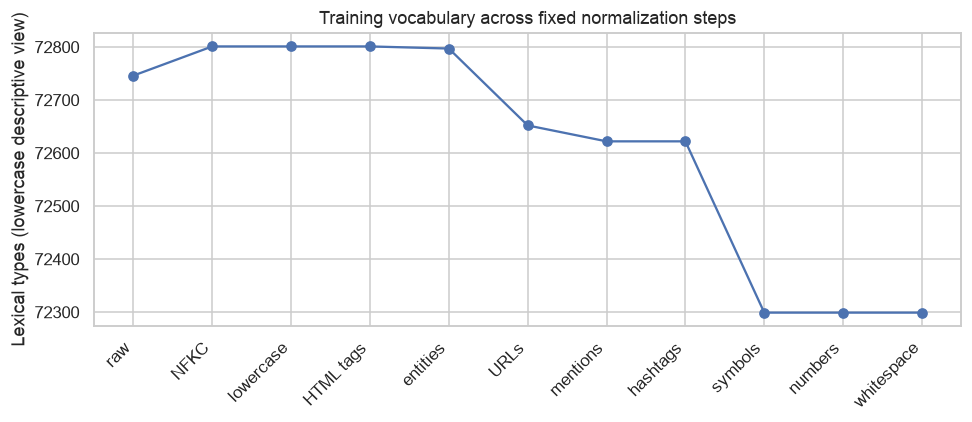

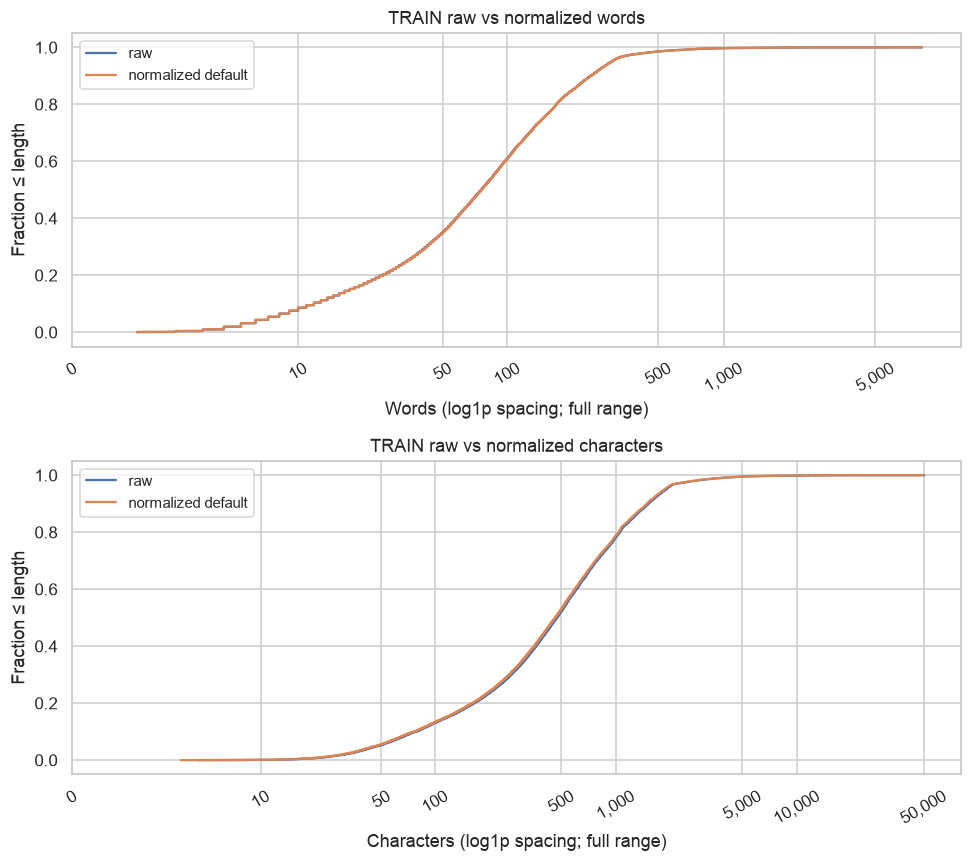

,TRAIN audit
default_empty_outputs,0
alternative_empty_outputs,0
numeric_signature_changed_docs,375
additional_default_duplicate_rows,12


row_id,raw_excerpt,normalized_excerpt


row_id,raw_excerpt,normalized_excerpt
451,"Vardhman Aluminum 80cm Pony Circular Knitting Pins, No 10, 11,12, White -Set of 3 The circular knitting pins have two pointed shanks joined by a long flexible cord. The cord is strong and smooth and allows the weight of",vardhman aluminum 80cm pony circular knitting pins no 10 11 12 white -set of 3 the circular knitting pins have two pointed shanks joined by a long flexible cord. the cord is strong and smooth and allows the weight of the
716,Classic Mosquito Net Classic Foldable Mosquito Net (Single Bed)With Free Saviours - (Pink) Classic mosquito net is made of polyester fabric and finest mesh which ensures super quality and restricts flies and mosquitoes f,classic mosquito net classic foldable mosquito net single bed with free saviours - pink classic mosquito net is made of polyester fabric and finest mesh which ensures super quality and restricts flies and mosquitoes from
1016,"The Canopy of Hope: Inclusive Education and Empowerment About the AuthorAn unusual alchemy of a Civil Servant with leadership and vision and an academic with a yen for research, Dr. Satya Narayan Misra has been the voice",the canopy of hope inclusive education and empowerment about the authoran unusual alchemy of a civil servant with leadership and vision and an academic with a yen for research dr. satya narayan misra has been the voice o


In [18]:
normalization_table=pd.DataFrame(step_records)
compact=pd.DataFrame({"Step":normalization_table.step,
    "Changed documents":[f"{n:,} ({p:.2f}%)" for n,p in zip(normalization_table.changed_N,normalization_table.changed_pct)],
    "V before → after":[f"{a:,} → {b:,}" for a,b in zip(normalization_table.V_before,normalization_table.V_after)],
    "Lost / new":[f"{a:,} / {b:,}" for a,b in zip(normalization_table.types_lost,normalization_table.types_new)],
    "Set Δ %":normalization_table.vocab_set_change_pct.round(3),
    "Size ↓ %":normalization_table.vocab_size_reduction_pct.round(3)})
show_table(compact,"Primary TRAIN impact: fixed training population",index=False)
length_columns=["step","word_mean","word_median","word_P95","char_mean","char_median","char_P95","empty_total","became_empty"]
length_table=pd.concat([pd.DataFrame([{"step":"raw",**raw_length_stats,"became_empty":0}]),
                         normalization_table[length_columns]],ignore_index=True)
for metric in ["word","char"]:
    part=length_table[["step",f"{metric}_mean",f"{metric}_median",f"{metric}_P95"]]
    show_table(part.round(2),f"TRAIN {metric} lengths after each operation",index=False)
show_table(length_table[["step","empty_total","became_empty"]],
           "TRAIN empty outputs: fixed population retained",collapse=True,index=False)
show_table(pd.DataFrame(step_examples),"Real per-operation before/after windows (escaped; abbreviated)",collapse=True,index=False)

normalized_train=train_views["whitespace"]
alternative_train=train_views["symbols"].map(drop_standalone_numbers).map(normalize_whitespace)
default_vocab=vocabulary(normalized_train);alternative_vocab=vocabulary(alternative_train)
number_policy_table=pd.DataFrame([
    {"policy":"keep all numbers (default)","V":len(default_vocab),"changed_vs_default_N":0,
     "word_mean":normalized_train.map(lambda t:len(t.split())).mean(),"empty_N":int(normalized_train.eq("").sum())},
    {"policy":"remove standalone numeric tokens", "V":len(alternative_vocab),
     "changed_vs_default_N":int(normalized_train.ne(alternative_train).sum()),
     "word_mean":alternative_train.map(lambda t:len(t.split())).mean(),"empty_N":int(alternative_train.eq("").sum())}])
show_table(number_policy_table.round(3),"TRAIN-only number-policy sensitivity",index=False)
number_set_report=pd.Series({"types_lost_vs_default":len(default_vocab-alternative_vocab),
                              "types_new_vs_default":len(alternative_vocab-default_vocab),
                              "standalone_removal_set_change_pct":100*len(default_vocab^alternative_vocab)/len(default_vocab)},name="measured")
show_table(number_set_report.to_frame().round(4))
number_rows=normalized_train.index[normalized_train.ne(alternative_train)][:3]
show_table(pd.DataFrame({"row_id":train.loc[number_rows,"row_id"],
    "default_excerpt":normalized_train.loc[number_rows].str.slice(0,200),
    "remove_standalone_excerpt":alternative_train.loc[number_rows].str.slice(0,200)}),
    "Real number-policy examples",collapse=True,index=False)

fig,ax=plt.subplots(figsize=(9,4))
plot_v=[len(vocabulary(train.text)),*normalization_table.V_after.tolist()]
ax.plot(range(len(plot_v)),plot_v,marker="o")
ax.set_xticks(range(len(plot_v)),["raw",*normalization_table.step],rotation=45,ha="right")
ax.set(ylabel="Lexical types (lowercase descriptive view)",title="Training vocabulary across fixed normalization steps")
plt.tight_layout();plt.show()
fig,axes=plt.subplots(2,1,figsize=(9,8))
for ax,metric in zip(axes,["words","characters"]):
    for name,series in [("raw",train.text),("normalized default",normalized_train)]:
        values=series.map(lambda t:len(t.split()) if metric=="words" else len(t)).to_numpy()
        ordered=np.sort(values)
        ax.plot(np.log1p(ordered),np.arange(1,len(values)+1)/len(values),label=name)
    ticks=np.array([0,10,50,100,500,1000,5000,10000,50000])
    ticks=ticks[ticks<=max(len(t) if metric=="characters" else len(t.split()) for t in train.text)]
    ax.set_xticks(np.log1p(ticks),[f"{x:,}" for x in ticks],rotation=30)
    ax.set(xlabel=f"{metric.capitalize()} (log1p spacing; full range)",ylabel="Fraction ≤ length",
           title=f"TRAIN raw vs normalized {metric}")
    ax.legend(fontsize=10)
plt.tight_layout();plt.show()

# Risk screens, not semantic judgments: numerical signatures and induced text collisions.
def numeric_signature(text): return re.findall(r"\d+(?:[.,]\d+)*",unicodedata.normalize("NFKC",text))
numeric_changed=pd.Series([numeric_signature(a)!=numeric_signature(b) for a,b in zip(train.text,normalized_train)],index=train.index)
empty_mask=normalized_train.eq("")
normalization_risks=pd.Series({"default_empty_outputs":int(empty_mask.sum()),
                                "alternative_empty_outputs":int(alternative_train.eq("").sum()),
                                "numeric_signature_changed_docs":int(numeric_changed.sum()),
                                "additional_default_duplicate_rows":int(normalized_train.duplicated().sum())},name="TRAIN audit")
show_table(normalization_risks.to_frame())
for name,mask in [("Empty default outputs",empty_mask),("Changed numeric signatures — review candidates",numeric_changed)]:
    ids=mask.index[mask][:3]
    show_table(pd.DataFrame({"row_id":train.loc[ids,"row_id"],"raw_excerpt":train.loc[ids,"text"].str.slice(0,220),
                             "normalized_excerpt":normalized_train.loc[ids].str.slice(0,220)}),name,collapse=True,index=False)
display(prose(f"**Observed:** default normalization changes **{int(train.text.ne(normalized_train).sum()):,}** "
              f"training texts; vocabulary **{len(vocabulary(train.text)):,} → {len(default_vocab):,}**. "
              f"Removing standalone numbers would additionally change **{int(normalized_train.ne(alternative_train).sum()):,}** "
              f"documents and lose **{len(default_vocab-alternative_vocab):,}** lexical types. "
              f"Default empty outputs = **{int(empty_mask.sum())}**; changed numeric signatures = "
              f"**{int(numeric_changed.sum())}**. These risk screens do not certify semantic equivalence. "
              "Keep all records in subsequent comparisons and review meaningful symbol/number changes before deployment."))

### Common tokenizer input and four method definitions

The light view applies **NFKC → recognized tag removal → entity decoding → whitespace**.
It keeps case, URLs, handles, numeric tokens, punctuation and sentence delimiters. Every
strategy sees the same training records and the same internal-assessment records in the same
order. No truncation, padding or strategy-specific filtering occurs, even for empty inputs.

- **Word:** NLTK English Punkt segmentation followed by `TreebankWordTokenizer` on each sentence.
  Most punctuation becomes tokens; common contractions split (for example `don't` → `do`, `n't`).
  Penn Treebank quote conventions can alter token spelling. Whitespace is not a token.
  See [NLTK's tokenizer specification](https://www.nltk.org/api/nltk.tokenize.treebank.html).
- **Sentence:** one Punkt-produced sentence string is one token, with case and its internal
  punctuation/spaces retained. Vocabulary means **whole training sentences**, not word types.
  The English Punkt tables are an external boundary model, not fitted on this test corpus;
  catalog fragments, abbreviations and model IDs can challenge those boundaries.
- **Character:** one Python Unicode code point per token, **including whitespace and punctuation**.
  This is neither bytes nor grapheme clusters.
- **BPE:** Hugging Face `tokenizers`, trained **from scratch on TRAIN only**, target vocabulary
  8,000, minimum pair frequency 2. No internal normalizer, ByteLevel pre-tokenizer with
  `add_prefix_space=False`, `use_regex=True`, all 256 byte alphabet symbols, ByteLevel decoder,
  and one special `[UNK]` token. No post-processor or inserted special tokens. The model
  vocabulary includes the guaranteed alphabet and `[UNK]`, even when some entries are unused.
  Compare with observed training token types in the supporting table. See the
  [training-from-memory API](https://huggingface.co/docs/tokenizers/training_from_memory).

Vocabulary fitting and normalizer choices are frozen before test encoding. Single-pass timings
include tokenization and counter/length accumulation for each partition; BPE training is timed
separately. Resource download, input preparation and notebook display are excluded. Timings are
machine/load dependent; they are not a controlled throughput ranking.

In [19]:
benchmark_train=train[["row_id","label"]].assign(input=train.text.map(light_input))
benchmark_test=test[["row_id","label"]].assign(input=test.text.map(light_input))
assert benchmark_train.input.notna().all() and benchmark_test.input.notna().all()
assert benchmark_train.row_id.tolist()==train.row_id.tolist()
assert benchmark_test.row_id.tolist()==test.row_id.tolist()
light_train_audit=pd.Series({"training_documents":len(benchmark_train),
    "changed_from_raw_N":int(benchmark_train.input.ne(train.text).sum()),
    "empty_light_inputs":int(benchmark_train.input.eq("").sum()),
    "documents_with_sentence_punctuation":int(benchmark_train.input.str.contains(r"[.!?]",regex=True).sum())},name="measured")
show_table(light_train_audit.to_frame())

fit_started=perf_counter()
bpe_fitting_row_ids=tuple(benchmark_train.row_id)
assert set(bpe_fitting_row_ids).isdisjoint(benchmark_test.row_id)
bpe=fit_bpe(iter(benchmark_train.input),vocab_size=8000,min_frequency=2)
bpe_fit_seconds=perf_counter()-fit_started
bpe_before_assessment=hashlib.sha256(bpe.to_str().encode()).hexdigest()
unk_id=bpe.token_to_id("[UNK]")
assert unk_id is not None and len(pre_tokenizers.ByteLevel.alphabet())==256
bpe_configuration=pd.Series({"requested_vocab_size":8000,"actual_vocab_size":bpe.get_vocab_size(),
    "min_frequency":2,"initial_byte_alphabet":256,"UNK_ID":unk_id,
    "fit_documents":len(bpe_fitting_row_ids),"fit_seconds":bpe_fit_seconds,
    "test_documents_used_for_training":0,"normalizer":"None","post_processor":"None",
    "padding":"disabled","truncation":"disabled"},name="observed")
show_table(bpe_configuration.to_frame(),"BPE configuration and training provenance")

def word_tokens(text):
    return [token for sentence in sentence_tokenizer.tokenize(text) for token in word_tokenizer.tokenize(sentence)]

def sentence_tokens(text): return sentence_tokenizer.tokenize(text)
def character_tokens(text): return list(text)
def bpe_ids(text): return bpe.encode(text,add_special_tokens=False).ids
strategies={"Word (NLTK)":word_tokens,"Sentence (Punkt)":sentence_tokens,
            "Character":character_tokens,"Byte-level BPE":bpe_ids}

# Every method consumes the identical common-input Series; only the unit changes.
def scan_tokens(texts,function):
    started=perf_counter();counter=Counter();lengths=[]
    for text in texts:
        tokens=function(text);counter.update(tokens);lengths.append(len(tokens))
    return counter,np.array(lengths,dtype=np.int64),perf_counter()-started

benchmark_rows=[];token_counts={};token_lengths={}
for name,function in strategies.items():
    train_counter,train_lengths,train_seconds=scan_tokens(benchmark_train.input,function)
    training_vocabulary=set(train_counter)  # Frozen before reading any assessment tokens.
    test_counter,test_lengths,test_seconds=scan_tokens(benchmark_test.input,function)
    if name=="Byte-level BPE":
        unknown=test_counter.get(unk_id,0);test_total=sum(test_counter.values())
        rate=unknown/test_total if test_total else np.nan
        vocab_size=bpe.get_vocab_size()
    else:
        unknown,test_total,rate=oov_counts(test_counter,training_vocabulary)
        vocab_size=len(training_vocabulary)
    benchmark_rows.append({"method":name,"training_vocabulary":vocab_size,
        "observed_train_types":len(train_counter),"OOV_occurrences":unknown,"test_token_occurrences":test_total,
        "OOV_pct":100*rate,"train_mean":train_lengths.mean(),"train_median":np.median(train_lengths),
        "train_P95":np.quantile(train_lengths,.95),"test_mean":test_lengths.mean(),
        "test_median":np.median(test_lengths),"test_P95":np.quantile(test_lengths,.95),
        "train_seconds":train_seconds,"test_seconds":test_seconds,
        "train_empty_sequences":int((train_lengths==0).sum()),"test_empty_sequences":int((test_lengths==0).sum())})
    token_counts[name]=(train_counter,test_counter)
    token_lengths[name]=(train_lengths,test_lengths)
benchmark_table=pd.DataFrame(benchmark_rows).set_index("method")
assert hashlib.sha256(bpe.to_str().encode()).hexdigest()==bpe_before_assessment
# A literal special-token spelling would be ambiguous with an unknown-ID count; report it.
literal_unk_documents=int(benchmark_test.input.str.contains("[UNK]",regex=False).sum())
show_table(benchmark_table[["training_vocabulary","OOV_pct","test_mean","test_median","test_P95"]].round(4),
           "Four tokenizers: training vocabulary and internal-assessment coverage/length")
show_table(benchmark_table[["observed_train_types","OOV_occurrences","test_token_occurrences", "OOV_pct"]].round(6),
           "OOV numerators/denominators and observed training types")
show_table(benchmark_table[["train_mean","train_median","train_P95","train_empty_sequences","test_empty_sequences"]].round(3),
           "Training sequence lengths; zero-length sequences are retained")
show_table(benchmark_table[["train_seconds","test_seconds"]].round(3),"Single-pass processing seconds")
print("BPE fitting seconds:",round(bpe_fit_seconds,3),"| Literal [UNK] spelling in assessment inputs:",literal_unk_documents)
print("BPE model hash unchanged after assessment encoding:",bpe_before_assessment)

# Known-answer diagnostic, independent of the real corpus and not included in any benchmark.
hand_unknown,hand_total,hand_rate=oov_counts(Counter(["known","new","known"]),{"known"})
assert (hand_unknown,hand_total)==(1,3) and np.isclose(hand_rate,1/3)
print(f"Hand-check occurrence OOV: {hand_unknown}/{hand_total} = {hand_rate:.6f}")

,measured
training_documents,22201
changed_from_raw_N,7063
empty_light_inputs,0
documents_with_sentence_punctuation,18177


,observed
requested_vocab_size,8000
actual_vocab_size,8000
min_frequency,2
initial_byte_alphabet,256
UNK_ID,0
fit_documents,22201
fit_seconds,1.691758
test_documents_used_for_training,0
normalizer,None
post_processor,None


,training_vocabulary,OOV_pct,test_mean,test_median,test_P95
method,,,,,
Word (NLTK),129915,3.0714,129.0321,87.0,349.5
Sentence (Punkt),101499,75.6723,5.5197,3.0,16.0
Character,440,0.0029,698.4125,470.0,1872.5
Byte-level BPE,8000,0.0000,181.6828,121.0,487.0


,observed_train_types,OOV_occurrences,test_token_occurrences,OOV_pct
method,,,,
Word (NLTK),129915,21999,716257,3.071384
Sentence (Punkt),101499,23186,30640,75.672324
Character,440,112,3876888,0.002889
Byte-level BPE,7914,0,1008521,0.000000


,train_mean,train_median,train_P95,train_empty_sequences,test_empty_sequences
method,,,,,
Word (NLTK),128.678,87.0,351.0,0,0
Sentence (Punkt),5.550,3.0,16.0,0,0
Character,694.507,470.0,1881.0,0,0
Byte-level BPE,179.707,120.0,491.0,0,0


,train_seconds,test_seconds
method,,
Word (NLTK),11.744,2.847
Sentence (Punkt),2.375,0.574
Character,0.463,0.119
Byte-level BPE,5.953,1.485


BPE fitting seconds: 1.692 | Literal [UNK] spelling in assessment inputs: 0
BPE model hash unchanged after assessment encoding: 8c21df6a3bdfe1beb7ebb965a3746a45c91c7e181d602c4c9f85ec947e214e41
Hand-check occurrence OOV: 1/3 = 0.333333


### Same-document segmentation example and interpretation

Choose the first training light-input text with 120–500 characters and at least two Punkt
sentences; this selection is for display only. Tokenize its **entire** common input with every
method. Show up to 24 tokens and at most 650 display characters per list, explicitly reporting
full token count and hidden tokens. Byte-level display glyphs such as `Ġ` encode byte/space
information and are not literal input characters. A decode roundtrip checks the common input.

In [20]:
example_candidates=benchmark_train.loc[benchmark_train.input.str.len().between(120,500)]
example_index=next(i for i,t in example_candidates.input.items() if len(sentence_tokens(t))>=2)
example_text=benchmark_train.loc[example_index,"input"]
show_table(pd.DataFrame([{"row_id":int(benchmark_train.loc[example_index,"row_id"]),"same_full_input":example_text}]),index=False)
example_rows=[]
for name,function in strategies.items():
    tokens=function(example_text)
    visible=bpe.encode(example_text,add_special_tokens=False).tokens if name=="Byte-level BPE" else tokens
    displayed=repr(visible[:24])
    example_rows.append({"method":name,"full_token_count":len(tokens),"hidden_tokens_after_24":max(0,len(tokens)-24),
                         "first_tokens":displayed[:650],"display_characters_omitted":max(0,len(displayed)-650)})
example_table=pd.DataFrame(example_rows)
example_display=pd.DataFrame({"Method":example_table.method,
    "Total / hidden tokens":[f"{a} / {b}" for a,b in zip(example_table.full_token_count,example_table.hidden_tokens_after_24)],
    "Token excerpt":[text+(f" … [{n} display characters omitted]" if n else "")
                     for text,n in zip(example_table.first_tokens,example_table.display_characters_omitted)]})
show_table(example_display,"Identical input; different token units",index=False)
assert bpe.decode(bpe.encode(example_text,add_special_tokens=False).ids,skip_special_tokens=False)==example_text

display(prose(f"**Observed:** word-level OOV = **{benchmark_table.loc['Word (NLTK)','OOV_pct']:.3f}%**; "
              f"sentence-level OOV = **{benchmark_table.loc['Sentence (Punkt)','OOV_pct']:.3f}%**. "
              "New whole sentences can contain entirely familiar words, so sentence OOV does not imply "
              "unknown constituent vocabulary. Case and punctuation also distinguish sentence strings."))
display(prose(f"**Observed:** character vocabulary = **{int(benchmark_table.loc['Character','training_vocabulary']):,}**, "
              f"but mean assessment sequence length = **{benchmark_table.loc['Character','test_mean']:.1f}** code points. "
              f"BPE uses **{int(benchmark_table.loc['Byte-level BPE','training_vocabulary']):,}** model entries, "
              f"mean length **{benchmark_table.loc['Byte-level BPE','test_mean']:.1f}** and OOV "
              f"**{benchmark_table.loc['Byte-level BPE','OOV_pct']:.3f}%**. With all 256 bytes covered, "
              "zero unknown IDs is a design consequence, not evidence of better product classification. "
              "No accuracy claim follows without a controlled classifier comparison."))

row_id,same_full_input
10,"Painting Mantra Art Street - Jardin Bird Framed Art Print Set of 4 Black (10 x 10 inch) Color:Color - Black ||Theme - Jardin Black Breath new life into your home and office with this original painting re-print. These high quality printed canvas are of size 10 inch by 10 inch, comes framed and ready to hang. Note: Print doesn't need any glass for protection and hence this comes without the glass."


Method,Total / hidden tokens,Token excerpt
Word (NLTK),82 / 58,"['Painting', 'Mantra', 'Art', 'Street', '-', 'Jardin', 'Bird', 'Framed', 'Art', 'Print', 'Set', 'of', '4', 'Black', '(', '10', 'x', '10', 'inch', ')', 'Color', ':', 'Color', '-']"
Sentence (Punkt),3 / 0,"['Painting Mantra Art Street - Jardin Bird Framed Art Print Set of 4 Black (10 x 10 inch) Color:Color - Black ||Theme - Jardin Black Breath new life into your home and office with this original painting re-print.', 'These high quality printed canvas are of size 10 inch by 10 inch, comes framed and ready to hang.', ""Note: Print doesn't need any glass for protection and hence this comes without the glass.""]"
Character,398 / 374,"['P', 'a', 'i', 'n', 't', 'i', 'n', 'g', ' ', 'M', 'a', 'n', 't', 'r', 'a', ' ', 'A', 'r', 't', ' ', 'S', 't', 'r', 'e']"
Byte-level BPE,98 / 74,"['P', 'ain', 'ting', 'ĠM', 'ant', 'ra', 'ĠArt', 'ĠStreet', 'Ġ-', 'ĠJ', 'ard', 'in', 'ĠBird', 'ĠFram', 'ed', 'ĠArt', 'ĠPrint', 'ĠSet', 'Ġof', 'Ġ4', 'ĠBlack', 'Ġ(', '10', 'Ġx']"


## Discussion

Canonical deduplication changes the unit from raw listing occurrence to one canonical text.
The frozen stratified split makes the later comparisons reproducible but remains an internal
post-EDA assessment with possible family dependence. Train-only normalization tables isolate
mechanical changes without selecting configurations on OOV. URLs, handle-shaped fragments,
hashtag markers and numerical content are not automatically useless; the examples and risk
screens make the provisional information trade-offs visible.

The displayed mention example removes **`@home`**, a brand-like product string; this is
concrete evidence that mention-shaped syntax need not be a social account or useless noise.
The hashtag example strips `#` from a replacement-part number while keeping the number.
The numeric-signature screen also flags punctuation changes such as a comma-separated size
list becoming separate numbers; it is not a count of lost digits or confirmed meaning errors.
A small number of training strings collide after normalization, reinforcing the need to review
lossy mappings before model evaluation.

The default keeps numbers and measurement/identifier punctuation. The standalone-number
alternative shows how much a seemingly narrow rule can change; it does not establish an
accuracy winner. Lowercase diagnostics can have zero set change by construction; removals and
newly joined/folded types can change membership even when vocabulary size barely moves.
Empty outputs and induced text collisions are reported and retained; future models must
specify a fixed empty-input policy rather than filtering each benchmark differently.

The common light input protects sentence boundaries for a fair unit comparison. Treebank
word tokens remain interpretable but can encounter new codes and spellings; character coverage
is broad with long sequences; BPE changes the granularity trade-off; whole-sentence vocabularies
measure repeated sentence strings. None is an absolute ranking. Vocabulary fitting is
training-only, English Punkt is an external segmentation resource, byte alphabet coverage is
engineered, and timings reflect a single run on the reported environment.

In [21]:
decision_table=pd.DataFrame([
 {"Decision":"Canonical-unique, stratified seed-42 protocol",
  "Evidence":f"{len(corpus):,} records; train/test={len(train):,}/{len(test):,}; 0 row/group overlap; {len(near_examples)} related train pairs in {near_candidates} biased candidates",
  "Trade-off":"Reproducible exact/canonical boundary; product variants and all-corpus EDA exposure remain",
  "To validate in Stage 03–04":"Recreate with make_text_protocol; use training CV and consider family-aware sensitivity before any generalization claim"},
 {"Decision":"Keep numeric content by default",
  "Evidence":f"Standalone removal changes {int(normalized_train.ne(alternative_train).sum()):,} training texts; loses {len(default_vocab-alternative_vocab):,} lexical types",
  "Trade-off":"Retains model IDs, sizes and quantities; larger and more fragmented vocabulary",
  "To validate in Stage 03–04":"Compare downstream information/performance on fixed training folds, without tuning on internal assessment"},
 {"Decision":"Conditional symbols; preserve original text",
  "Evidence":f"Final V={len(default_vocab):,}; empty outputs={int(empty_mask.sum())}; changed numerical signatures={int(numeric_changed.sum())}",
  "Trade-off":"Less decorative syntax; punctuation and some mentions/provenance can carry meaning",
  "To validate in Stage 03–04":"Inspect affected examples; compare information/performance and keep the same row population"},
 {"Decision":"One light input for all tokenizers",
  "Evidence":f"Four methods each process {len(train):,} training and {len(test):,} assessment records; sentence punctuation retained",
  "Trade-off":"Meaningful unit comparison; different vocabulary/length/OOV definitions remain incomparable as accuracy ranks",
  "To validate in Stage 03–04":"Use a fixed input policy in stopword, morphology and representation comparisons"},
 {"Decision":"Train-only BPE, fixed 8,000 target",
  "Evidence":f"Actual V={bpe.get_vocab_size():,}; unknown-ID OOV={benchmark_table.loc['Byte-level BPE','OOV_pct']:.4f}%; model hash unchanged after assessment",
  "Trade-off":"Byte coverage avoids unknown IDs but can produce long or uninterpretable fragments",
  "To validate in Stage 03–04":"Assess representations and classifiers on training CV; do not choose vocabulary size from assessment OOV"},
 {"Decision":"Defer tokenizer performance ranking",
  "Evidence":f"Word/sentence OOV={benchmark_table.loc['Word (NLTK)','OOV_pct']:.3f}%/{benchmark_table.loc['Sentence (Punkt)','OOV_pct']:.3f}%; no classifier fitted",
  "Trade-off":"Coverage evidence alone cannot identify predictive accuracy or semantic retention",
  "To validate in Stage 03–04":"Stopword MI/Naive Bayes and morphology Logistic Regression CV, then representation comparisons"},
])
show_table(decision_table,index=False)

Decision,Evidence,Trade-off,To validate in Stage 03–04
"Canonical-unique, stratified seed-42 protocol","27,752 records; train/test=22,201/5,551; 0 row/group overlap; 123 related train pairs in 300 biased candidates",Reproducible exact/canonical boundary; product variants and all-corpus EDA exposure remain,Recreate with make_text_protocol; use training CV and consider family-aware sensitivity before any generalization claim
Keep numeric content by default,"Standalone removal changes 13,785 training texts; loses 1,086 lexical types","Retains model IDs, sizes and quantities; larger and more fragmented vocabulary","Compare downstream information/performance on fixed training folds, without tuning on internal assessment"
Conditional symbols; preserve original text,"Final V=72,299; empty outputs=0; changed numerical signatures=375",Less decorative syntax; punctuation and some mentions/provenance can carry meaning,Inspect affected examples; compare information/performance and keep the same row population
One light input for all tokenizers,"Four methods each process 22,201 training and 5,551 assessment records; sentence punctuation retained",Meaningful unit comparison; different vocabulary/length/OOV definitions remain incomparable as accuracy ranks,"Use a fixed input policy in stopword, morphology and representation comparisons"
"Train-only BPE, fixed 8,000 target","Actual V=8,000; unknown-ID OOV=0.0000%; model hash unchanged after assessment",Byte coverage avoids unknown IDs but can produce long or uninterpretable fragments,Assess representations and classifiers on training CV; do not choose vocabulary size from assessment OOV
Defer tokenizer performance ranking,Word/sentence OOV=3.071%/75.672%; no classifier fitted,Coverage evidence alone cannot identify predictive accuracy or semantic retention,"Stopword MI/Naive Bayes and morphology Logistic Regression CV, then representation comparisons"


## Conclusion

Stage 02 implements the normalization/tokenization part of the rubric: a reproducible
raw-to-corpus/split protocol, train-only per-step vocabulary and length impact, a number-policy
sensitivity, and four same-input tokenizers with training vocabulary, occurrence OOV and
sequence-length summaries. The output tables and plots are computed in this notebook and
saved for data-free static rendering. No normalization policy or tokenizer is declared best
for classification.

Next: **Stage 03 — Stopwords and morphology** will compare stopword vocabulary/information,
MI and Naive Bayes, then Porter/Snowball/WordNet collision rates and Logistic Regression CV.
**Stage 04 — Representations** remains planned. Those notebooks do not exist yet; see the
[roadmap](index.md). Stage 01/02 are implemented, but Part B and the whole assignment remain
incomplete. Later chapters must re-read raw data and call the same protocol helper, not reuse
an executed notebook or a required processed cache.

In [22]:
pd.testing.assert_frame_equal(raw,raw_snapshot)
raw_sha256_after=hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
assert raw_sha256_after==raw_sha256_before
show_table(pd.Series({"before":raw_sha256_before,"after":raw_sha256_after},name="Raw SHA-256").to_frame())
for function in [unicode_nfkc,lowercase,remove_html_tags,decode_entities,remove_urls,remove_mentions,
                 remove_hashtag_marker,conditional_symbols,keep_numbers,drop_standalone_numbers,
                 normalize_whitespace,light_input]:
    assert pd.isna(function(pd.NA)) and pd.isna(function(None)) and function("")==""
assert len(normalization_table)==10 and len(benchmark_table)==4
assert all(len(lengths[0])==len(train) and len(lengths[1])==len(test) for lengths in token_lengths.values())
assert hashlib.sha256(bpe.to_str().encode()).hexdigest()==bpe_before_assessment
print("Raw frame/CSV unchanged; missing/empty guards, fixed populations, split separation and frozen BPE verified.")
print("Stage 02 evidence saved; no full corpus, split manifest or tokenizer cache exported.")

,Raw SHA-256
before,1d44be1780bc9558f40ab4cee5b32051ddfe90647cd525b9652b47cdb233593f
after,1d44be1780bc9558f40ab4cee5b32051ddfe90647cd525b9652b47cdb233593f


Raw frame/CSV unchanged; missing/empty guards, fixed populations, split separation and frozen BPE verified.
Stage 02 evidence saved; no full corpus, split manifest or tokenizer cache exported.
